In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
pip install -q torch torchvision transformers timm pycocotools


In [ ]:
import torch
from transformers import DetrForObjectDetection, DetrImageProcessor
from torchvision.datasets import CocoDetection
from torch.utils.data import DataLoader
from torch.optim import AdamW


In [ ]:
processor = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50")

model = DetrForObjectDetection.from_pretrained(
    "facebook/detr-resnet-50",
    num_labels=1,               # corrosion only
    ignore_mismatched_sizes=True
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pas

DetrForObjectDetection(
  (model): DetrModel(
    (backbone): DetrConvModel(
      (conv_encoder): DetrConvEncoder(
        (model): FeatureListNet(
          (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (bn1): DetrFrozenBatchNorm2d()
          (act1): ReLU(inplace=True)
          (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
          (layer1): Sequential(
            (0): Bottleneck(
              (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn1): DetrFrozenBatchNorm2d()
              (act1): ReLU(inplace=True)
              (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
              (bn2): DetrFrozenBatchNorm2d()
              (drop_block): Identity()
              (act2): ReLU(inplace=True)
              (aa): Identity()
              (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

In [ ]:
def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


In [ ]:
train_dataset = CocoDetection(
    root="/content/drive/MyDrive/DatasetKorosi_COCO/train/images",
    annFile="/content/drive/MyDrive/DatasetKorosi_COCO/train/_annotations.coco.json"
)

val_dataset = CocoDetection(
    root="/content/drive/MyDrive/DatasetKorosi_COCO/valid/images",
    annFile="/content/drive/MyDrive/DatasetKorosi_COCO/valid/_annotations.coco.json"
)


loading annotations into memory...
Done (t=2.58s)
creating index...
index created!
loading annotations into memory...
Done (t=0.64s)
creating index...
index created!


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=4,      # kecil karena Transformer
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)


In [ ]:
import os

save_root = "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_only_DETR"
os.makedirs(save_root, exist_ok=True)

optimizer = AdamW(model.parameters(), lr=1e-4)
epochs = 30
start_epoch = 0


In [ ]:
from tqdm import tqdm

optimizer = AdamW(model.parameters(), lr=1e-4)
epochs = 30

for epoch in range(epochs):
    model.train()
    total_loss = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

    for step, (images, targets) in enumerate(progress_bar):
        pixel_values = []
        labels = []

        for img, ann in zip(images, targets):
            encoding = processor(images=img, return_tensors="pt")
            pixel_values.append(encoding["pixel_values"].squeeze(0))

            boxes = []
            class_labels = []

            for obj in ann:
                x, y, w, h = obj["bbox"]
                boxes.append([x, y, x + w, y + h])
                class_labels.append(0)  # corrosion

            labels.append({
                "class_labels": torch.tensor(class_labels, dtype=torch.long),
                "boxes": torch.tensor(boxes, dtype=torch.float32)
            })

        pixel_values = torch.stack(pixel_values).to(device)
        labels = [{k: v.to(device) for k, v in t.items()} for t in labels]

        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    print(f"\nEpoch [{epoch+1}/{epochs}] Average Loss: {avg_loss:.4f}")

    # ✅ SIMPAN SETIAP EPOCH (PENTING!)
    model.save_pretrained("/content/drive/MyDrive/CV_Corrosion_Project/Transformer_only_DETR")
    processor.save_pretrained("/content/drive/MyDrive/CV_Corrosion_Project/Transformer_only_DETR")


Epoch 1/30: 100%|██████████| 1382/1382 [54:53<00:00,  2.38s/it, loss=4.2e+3]



Epoch [1/30] Average Loss: 6395.0335


Epoch 2/30: 100%|██████████| 1382/1382 [14:47<00:00,  1.56it/s, loss=6.39e+3]



Epoch [2/30] Average Loss: 6394.6505


Epoch 3/30: 100%|██████████| 1382/1382 [14:47<00:00,  1.56it/s, loss=6.85e+3]



Epoch [3/30] Average Loss: 6401.2270


Epoch 4/30: 100%|██████████| 1382/1382 [14:47<00:00,  1.56it/s, loss=6.17e+3]



Epoch [4/30] Average Loss: 6393.1831


Epoch 5/30:  87%|████████▋ | 1201/1382 [12:52<01:56,  1.55it/s, loss=5.81e+3]


RuntimeError: cdist only supports at least 2D tensors, X2 got: 1D

In [ ]:
import torch
from transformers import DetrForObjectDetection, DetrImageProcessor
from torch.optim import AdamW

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

save_path = "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_only_DETR"

# LOAD MODEL TERAKHIR
model = DetrForObjectDetection.from_pretrained(save_path)
processor = DetrImageProcessor.from_pretrained(save_path)

model.to(device)


DetrForObjectDetection(
  (model): DetrModel(
    (backbone): DetrConvModel(
      (conv_encoder): DetrConvEncoder(
        (model): FeatureListNet(
          (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (bn1): DetrFrozenBatchNorm2d()
          (act1): ReLU(inplace=True)
          (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
          (layer1): Sequential(
            (0): Bottleneck(
              (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn1): DetrFrozenBatchNorm2d()
              (act1): ReLU(inplace=True)
              (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
              (bn2): DetrFrozenBatchNorm2d()
              (drop_block): Identity()
              (act2): ReLU(inplace=True)
              (aa): Identity()
              (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

In [ ]:
start_epoch = 8
total_epochs = 30
epochs_remaining = total_epochs - start_epoch


In [ ]:
from tqdm import tqdm

optimizer = AdamW(model.parameters(), lr=1e-4)

for epoch in range(start_epoch, total_epochs):
    model.train()
    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{total_epochs} (RESUME)"
    )

    for images, targets in progress_bar:
        pixel_values = []
        labels = []

        for img, ann in zip(images, targets):
            encoding = processor(images=img, return_tensors="pt")
            pixel_values.append(encoding["pixel_values"].squeeze(0))

            boxes = []
            class_labels = []

            for obj in ann:
                x, y, w, h = obj["bbox"]
                boxes.append([x, y, x + w, y + h])
                class_labels.append(0)

            labels.append({
                "class_labels": torch.tensor(class_labels, dtype=torch.long),
                "boxes": torch.tensor(boxes, dtype=torch.float32)
            })

        pixel_values = torch.stack(pixel_values).to(device)
        labels = [{k: v.to(device) for k, v in t.items()} for t in labels]

        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress_bar.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    print(f"\nEpoch [{epoch+1}/{total_epochs}] Average Loss: {avg_loss:.4f}")

    # 🔐 SIMPAN LAGI SETIAP EPOCH
    model.save_pretrained(save_path)
    processor.save_pretrained(save_path)


Epoch 9/30 (RESUME): 100%|██████████| 1382/1382 [1:12:19<00:00,  3.14s/it, loss=6.12e+3]



Epoch [9/30] Average Loss: 6392.4401


Epoch 10/30 (RESUME): 100%|██████████| 1382/1382 [03:33<00:00,  6.46it/s, loss=6.39e+3]



Epoch [10/30] Average Loss: 6395.8020


Epoch 11/30 (RESUME): 100%|██████████| 1382/1382 [03:40<00:00,  6.27it/s, loss=6.39e+3]



Epoch [11/30] Average Loss: 6397.5816


... (6 outputs left out)

Epoch 15/30 (RESUME): 100%|██████████| 1382/1382 [03:41<00:00,  6.24it/s, loss=7.75e+3]



Epoch [15/30] Average Loss: 6393.8438


Epoch 16/30 (RESUME):   1%|▏         | 20/1382 [00:03<04:11,  5.42it/s, loss=6.27e+3]


KeyboardInterrupt: 

In [ ]:
import torch
from transformers import DetrForObjectDetection, DetrImageProcessor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

save_path = "/content/drive/MyDrive/CV_Corrosion_Project/Transformer_only_DETR"

model = DetrForObjectDetection.from_pretrained(save_path)
processor = DetrImageProcessor.from_pretrained(save_path)

model.to(device)
model.eval()


DetrForObjectDetection(
  (model): DetrModel(
    (backbone): DetrConvModel(
      (conv_encoder): DetrConvEncoder(
        (model): FeatureListNet(
          (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
          (bn1): DetrFrozenBatchNorm2d()
          (act1): ReLU(inplace=True)
          (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
          (layer1): Sequential(
            (0): Bottleneck(
              (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
              (bn1): DetrFrozenBatchNorm2d()
              (act1): ReLU(inplace=True)
              (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
              (bn2): DetrFrozenBatchNorm2d()
              (drop_block): Identity()
              (act2): ReLU(inplace=True)
              (aa): Identity()
              (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# GANTI dengan salah satu gambar test kamu
image_path = "/content/drive/MyDrive/DatasetKorosi_COCO/test/images/000145_jpg.rf.acbb2dd3646cfb1028e098cbfd35d0a7.jpg"

image = Image.open(image_path).convert("RGB")

inputs = processor(images=image, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**inputs)

results = processor.post_process_object_detection(
    outputs,
    threshold=0.05,
    target_sizes=[image.size[::-1]]
)

print(results)


[{'scores': tensor([], device='cuda:0'), 'labels': tensor([], device='cuda:0', dtype=torch.int64), 'boxes': tensor([], device='cuda:0', size=(0, 4))}]


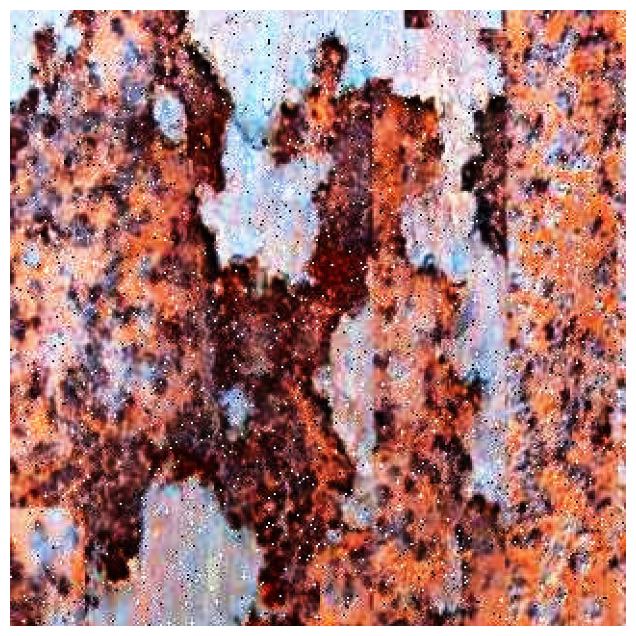

In [ ]:
import matplotlib.patches as patches

fig, ax = plt.subplots(1, figsize=(8, 8))
ax.imshow(image)

for score, label, box in zip(
    results[0]["scores"],
    results[0]["labels"],
    results[0]["boxes"]
):
    x1, y1, x2, y2 = box.tolist()
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )
    ax.add_patch(rect)
    ax.text(
        x1, y1,
        f"corrosion {score:.2f}",
        color="white",
        fontsize=10,
        bbox=dict(facecolor="red", alpha=0.5)
    )

plt.axis("off")
plt.show()


In [ ]:
import time

start = time.time()

with torch.no_grad():
    outputs = model(**inputs)

end = time.time()

print(f"Inference time: {(end - start)*1000:.2f} ms")


Inference time: 14.08 ms
